In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path
import pandas as pd

In [107]:
#PLT 한글 깨짐 방지코드
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

In [23]:
## 실습 1 — 설비 4대 분류

In [ ]:
#파일: `02-01_설비4대분류_30개_실습목록.csv`
#설비의 이름이 아니라 주된 물리 작동을 근거로 합니다.


In [33]:
BASE = Path.cwd().parents[1] / "lectures" / "week9" / "02_실습_20_261109_8"
eq = pd.read_csv(BASE / "02-01_설비4대분류_30개_실습목록.csv")

In [34]:
eq.head()

,번호,설비명,공정,주요_동작,분류_작성,분류_근거_작성
0,1,소결 주배풍기,원료·제선,회전으로 공기를 흡인·이송,NaN,NaN
1,2,고로 송풍기,원료·제선,회전으로 고압 공기를 공급,NaN,NaN
2,3,열풍로,원료·제선,축열·연소로 열풍을 생산,NaN,NaN
3,4,출선구 개공기,원료·제선,유압·공압 구동으로 출선구를 천공,NaN,NaN
4,5,머드건,원료·제선,유압으로 진흙을 압출·주입,NaN,NaN


In [32]:
분류["주요_동작"].unique().tolist()

['회전으로 공기를 흡인·이송',
 '회전으로 고압 공기를 공급',
 '축열·연소로 열풍을 생산',
 '유압·공압 구동으로 출선구를 천공',
 '유압으로 진흙을 압출·주입',
 '벨트로 원료를 연속 이송',
 '원료를 쌓고 회수해 이송',
 '고온 소결광을 냉각',
 '회전으로 분진 함유 가스를 흡인',
 '회전 임펠러로 냉각수를 이송',
 '회전 임펠러로 물을 가압·이송',
 '대차로 슬래그 용기를 운반',
 '구동 장치로 코크스를 밀어 배출',
 '유압 구동으로 전로를 회전·경동',
 '랜스를 상하 이송',
 '회전으로 배가스를 흡인',
 '크레인으로 래들을 들어 운반',
 '전극 또는 장치를 상하 이송',
 '대차로 턴디시를 위치 이동',
 '몰드를 왕복 진동',
 '롤 회전으로 주편을 지지·이송',
 '회전으로 냉각수를 가압·분사',
 '연소로 슬래브를 가열',
 '회전력으로 압연 롤을 구동',
 '유압으로 롤 간격을 조정',
 '회전 롤러로 제품을 이송',
 '회전 맨드릴로 코일을 권취',
 '회전 압축 요소로 공기를 압축',
 '펌프·밸브로 작동유를 가압·제어',
 '공기와 물의 열교환으로 냉각']

In [30]:
분류["공정"].unique()

<ArrowStringArray>
['원료·제선', '제강·연주', '압연·유틸리티']
Length: 3, dtype: str

In [28]:
#설비의 이름이 아니라 주된 물리 작동을 근거로 합니다.

In [ ]:
#각 설비의 `분류_작성`, `분류_근거_작성`을 채우세요. 
# 설비의 이름이 아니라 주된 물리 작동을 근거로 합니다.

In [36]:
# 설비 30개 목록 불러오기
eq = pd.read_csv(BASE / "02-01_설비4대분류_30개_실습목록.csv")

# 번호: 분류 (PDF 69쪽 기준, 8·18·21·30번은 PDF에 없어 유추)
cls = {
    1: "회전기계", 2: "회전기계", 3: "열설비", 4: "유압·공압", 5: "유압·공압",
    6: "반송", 7: "반송", 8: "열설비", 9: "회전기계", 10: "회전기계",
    11: "회전기계", 12: "반송", 13: "유압·공압", 14: "유압·공압", 15: "유압·공압",
    16: "회전기계", 17: "반송", 18: "유압·공압", 19: "반송", 20: "유압·공압",
    21: "반송", 22: "회전기계", 23: "열설비", 24: "회전기계", 25: "유압·공압",
    26: "반송", 27: "반송", 28: "회전기계", 29: "유압·공압", 30: "열설비",
}

# 번호: 근거 (주요_동작 표현 + PDF 근거)
why = {
    1: "회전으로 공기를 흡인·이송",
    2: "회전으로 고압 공기를 공급",
    3: "축열·연소로 열풍을 생산",
    4: "유압·공압 구동으로 천공",
    5: "유압으로 진흙을 압출·주입",
    6: "벨트로 원료를 연속 이송",
    7: "원료를 쌓고 회수해 이송",
    8: "고온 소결광을 냉각 (모호, PDF에 없음)",
    9: "회전으로 분진 함유 가스를 흡인",
    10: "회전 임펠러로 냉각수를 이송",
    11: "회전 임펠러로 물을 가압·이송",
    12: "대차로 슬래그 용기를 운반",
    13: "PDF 69쪽에서 코크스 압출기를 유압·공압으로 분류",
    14: "유압 구동으로 전로를 회전·경동",
    15: "PDF 69쪽에서 랜스 승강을 유압·공압으로 분류",
    16: "회전으로 배가스를 흡인",
    17: "크레인으로 래들을 들어 운반",
    18: "15번과 같은 상하 이송 동작이라 유추 (모호, PDF에 없음)",
    19: "대차로 턴디시를 위치 이동",
    20: "PDF 69쪽에서 몰드 오실레이터를 유압·공압으로 분류",
    21: "롤 회전으로 주편을 지지·이송 (모호, PDF에 없음)",
    22: "회전으로 냉각수를 가압·분사",
    23: "연소로 슬래브를 가열",
    24: "회전력으로 압연 롤을 구동",
    25: "유압으로 롤 간격을 조정",
    26: "PDF 69쪽에서 롤러테이블을 반송으로 분류",
    27: "PDF 69쪽에서 다운코일러를 반송으로 분류",
    28: "회전 압축 요소로 공기를 압축",
    29: "펌프·밸브로 작동유를 가압·제어",
    30: "공기와 물의 열교환으로 냉각",
}

# 번호 열 값을 딕셔너리로 바꿔 새 열에 대입
eq["분류_작성"] = eq["번호"].map(cls)
eq["분류_근거_작성"] = eq["번호"].map(why)

# 분류별 개수 확인
print(eq["분류_작성"].value_counts())

분류_작성
회전기계     9
유압·공압    9
반송       8
열설비      4
Name: count, dtype: int64


In [37]:
eq.head()

,번호,설비명,공정,주요_동작,분류_작성,분류_근거_작성
0,1,소결 주배풍기,원료·제선,회전으로 공기를 흡인·이송,회전기계,회전으로 공기를 흡인·이송
1,2,고로 송풍기,원료·제선,회전으로 고압 공기를 공급,회전기계,회전으로 고압 공기를 공급
2,3,열풍로,원료·제선,축열·연소로 열풍을 생산,열설비,축열·연소로 열풍을 생산
3,4,출선구 개공기,원료·제선,유압·공압 구동으로 출선구를 천공,유압·공압,유압·공압 구동으로 천공
4,5,머드건,원료·제선,유압으로 진흙을 압출·주입,유압·공압,유압으로 진흙을 압출·주입


In [40]:
#"""02-01 실습: 물리량·위치·주기 및 데이터 해상도를 확인하세요."""

In [38]:
from pathlib import Path
import pandas as pd

# 노트북 위치(practice/day31) 기준으로 lectures 폴더의 실습 데이터 경로 지정
BASE = Path.cwd().parents[1] / "lectures" / "week9" / "02_실습_20_261109_8"
spec = pd.read_csv(BASE / "02-01_측정의_3요소_설비태그목록.csv")
sample = pd.read_csv(
    BASE / "02-01_측정의_3요소_측정샘플.csv", parse_dates=["timestamp"]
)
print("사양 행 수:", len(spec), "/ 샘플 행 수:", len(sample))
print("컬럼:", sample.columns.tolist())


사양 행 수: 16 / 샘플 행 수: 120
컬럼: ['timestamp', 'MTR01_VIB_RMS_H', 'MTR01_CURRENT', 'MTR01_TEMP', 'HYD01_PRESS_IN', 'FUR01_TEMP_Z1']


In [41]:
# TODO 1: 각 컬럼에 대해 물리량, 단위, 설치 위치, 사양 주기를 정리하세요.

In [53]:
sample.info()

<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   timestamp        120 non-null    datetime64[us]
 1   MTR01_VIB_RMS_H  120 non-null    float64       
 2   MTR01_CURRENT    120 non-null    float64       
 3   MTR01_TEMP       120 non-null    float64       
 4   HYD01_PRESS_IN   120 non-null    float64       
 5   FUR01_TEMP_Z1    120 non-null    float64       
dtypes: datetime64[us](1), float64(5)
memory usage: 5.8 KB


In [54]:
sample.set_index("timestamp", inplace=True)
sample.sort_index(inplace=True)

In [56]:
sample.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 120 entries, 2026-03-02 08:00:00 to 2026-03-02 09:59:00
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   MTR01_VIB_RMS_H  120 non-null    float64
 1   MTR01_CURRENT    120 non-null    float64
 2   MTR01_TEMP       120 non-null    float64
 3   HYD01_PRESS_IN   120 non-null    float64
 4   FUR01_TEMP_Z1    120 non-null    float64
dtypes: float64(5)
memory usage: 5.6 KB


In [57]:
sample.head()

,MTR01_VIB_RMS_H,MTR01_CURRENT,MTR01_TEMP,HYD01_PRESS_IN,FUR01_TEMP_Z1
timestamp,,,,,
2026-03-02 08:00:00,1.8,62.5,48.0,152.0,1180.0
2026-03-02 08:01:00,1.9,63.0,48.0,153.0,1180.0
2026-03-02 08:02:00,1.8,62.0,48.5,152.0,1180.0
2026-03-02 08:03:00,2.0,64.0,48.5,210.0,1180.0
2026-03-02 08:04:00,1.9,63.5,49.0,210.0,1180.0


In [43]:
sample.tail()

,timestamp,MTR01_VIB_RMS_H,MTR01_CURRENT,MTR01_TEMP,HYD01_PRESS_IN,FUR01_TEMP_Z1
115,2026-03-02 09:55:00,2.0,64.0,54.0,152.0,1191.5
116,2026-03-02 09:56:00,2.2,64.5,54.0,154.0,1191.5
117,2026-03-02 09:57:00,2.1,63.5,54.0,152.0,1191.5
118,2026-03-02 09:58:00,2.4,66.0,54.0,151.0,1191.5
119,2026-03-02 09:59:00,2.1,64.5,54.0,153.0,1191.5


In [47]:
print('결측치 개수:', sample.isna().sum().sum())

결측치 개수: 0


In [49]:
print('중복 개수:', sample.duplicated().sum())

중복 개수: 0


In [58]:
# TODO 1: 각 컬럼에 대해 물리량, 단위, 설치 위치, 사양 주기를 정리하세요.

In [ ]:
#MTR01_VIB_RMS_H,1번 모터 구동측 수평 진동 실효값,mm/s,60,0,25,0.1,구동측 베어링 하우징 수평


In [59]:
sample.columns.tolist()

['MTR01_VIB_RMS_H',
 'MTR01_CURRENT',
 'MTR01_TEMP',
 'HYD01_PRESS_IN',
 'FUR01_TEMP_Z1']

In [109]:
# 컬럼 설명 카드
card = spec.set_index("tag").loc[sample.columns, ["description", "unit", "install_location", "sampling_sec",'range_max']]
card


,description,unit,install_location,sampling_sec,range_max
MTR01_VIB_RMS_H,1번 모터 구동측 수평 진동 실효값,mm/s,구동측 베어링 하우징 수평,60,25
MTR01_CURRENT,1번 모터 운전 전류,A,모터 제어반 전류 변성기,60,120
MTR01_TEMP,1번 모터 고정자 권선 온도,degC,고정자 권선 매입 측온저항체,60,180
HYD01_PRESS_IN,1번 유압 유닛 공급 압력,bar,펌프 토출 배관,60,210
FUR01_TEMP_Z1,1번 가열로 1존 분위기 온도,degC,1존 천장 열전대,300,1300


In [67]:
# TODO 2: timestamp 차이를 계산해 실제 저장 간격과 빠진/중복 시각을 확인하세요.
sample["timestamp_diff"] = sample.index.to_series().diff()

In [75]:
sample["timestamp_diff"].value_counts(dropna=False)

timestamp_diff
0 days 00:01:00    119
NaT                  1
Name: count, dtype: int64

In [ ]:
#?????

In [ ]:
print("중복:", sample.index.to_series().duplicated().sum())
#????

중복: 0


In [ ]:
# TODO 3: 사양 주기와 실제 파일 저장 간격이 다른 태그를 찾으세요.


In [90]:
sample.drop(columns="timestamp_diff", inplace=True)

In [91]:
sample

,MTR01_VIB_RMS_H,MTR01_CURRENT,MTR01_TEMP,HYD01_PRESS_IN,FUR01_TEMP_Z1
timestamp,,,,,
2026-03-02 08:00:00,1.8,62.5,48.0,152.0,1180.0
2026-03-02 08:01:00,1.9,63.0,48.0,153.0,1180.0
2026-03-02 08:02:00,1.8,62.0,48.5,152.0,1180.0
2026-03-02 08:03:00,2.0,64.0,48.5,210.0,1180.0
2026-03-02 08:04:00,1.9,63.5,49.0,210.0,1180.0
...,...,...,...,...,...
2026-03-02 09:55:00,2.0,64.0,54.0,152.0,1191.5
2026-03-02 09:56:00,2.2,64.5,54.0,154.0,1191.5
2026-03-02 09:57:00,2.1,63.5,54.0,152.0,1191.5


In [89]:
tags

['MTR01_VIB_RMS_H',
 'MTR01_CURRENT',
 'MTR01_TEMP',
 'HYD01_PRESS_IN',
 'FUR01_TEMP_Z1']

In [94]:
실제 = sample.index.to_series().diff().dt.total_seconds().median()

사양 = spec.set_index("tag").loc[tags, "sampling_sec"]

check = pd.DataFrame({"사양_주기": 사양, "실제_간격": 실제})
check["불일치"] = check["사양_주기"] != check["실제_간격"]
check


,사양_주기,실제_간격,불일치
tag,,,
MTR01_VIB_RMS_H,60,60.0,False
MTR01_CURRENT,60,60.0,False
MTR01_TEMP,60,60.0,False
HYD01_PRESS_IN,60,60.0,False
FUR01_TEMP_Z1,300,60.0,True


In [ ]:
#태그 목록(사양): 300초마다 저장
#측정 샘플 파일(실제): 시각이 1분(60초) 간격

In [110]:
# TODO 4: 각 신호의 관측 최소 변화 폭, 관측 최댓값, 최댓값 반복 횟수를 구하세요.
result = pd.DataFrame(index=sample.columns)
result["최솟값"] = sample.min()
result["최댓값"] = sample.max()
result["최대기준값"] = card['range_max']
result["최소 변화 폭"] = sample.diff().min()
result["사양 분해능"] = spec.set_index("tag").loc[sample.columns, "resolution"]
result["최댓값 반복 횟수"] = (sample == sample.max()).sum()

result


,최솟값,최댓값,최대기준값,최소 변화 폭,사양 분해능,최댓값 반복 횟수
MTR01_VIB_RMS_H,1.7,2.4,25,-0.3,0.1,6
MTR01_CURRENT,62.0,66.0,120,-1.5,0.5,6
MTR01_TEMP,48.0,54.0,180,0.0,0.5,40
HYD01_PRESS_IN,151.0,210.0,210,-58.0,1.0,14
FUR01_TEMP_Z1,1180.0,1191.5,1300,0.0,0.5,5


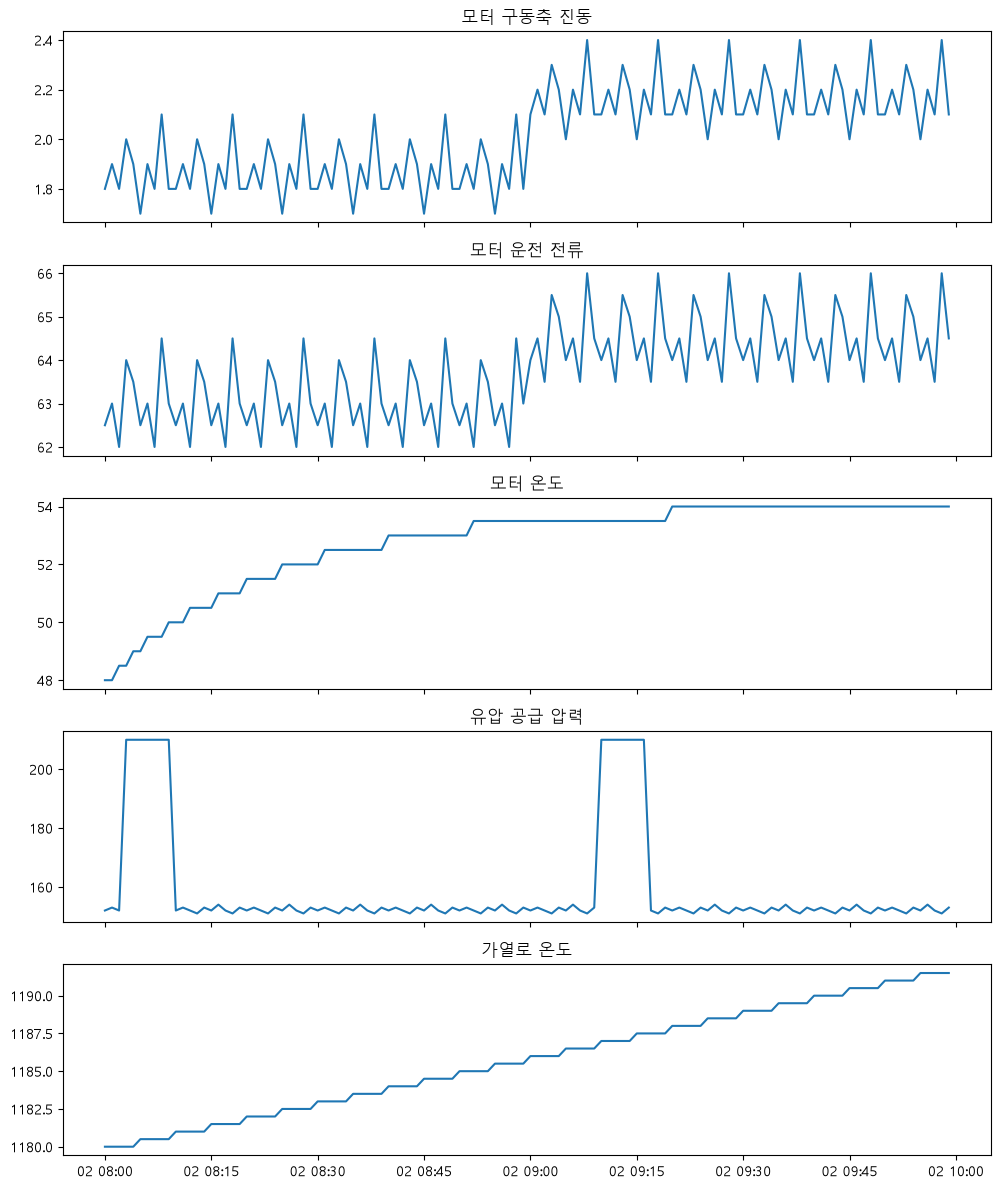

In [108]:
fig, axes = plt.subplots(5, 1, figsize=(10, 12), sharex=True)
axes[0].set_title('모터 구동축 진동')
axes[1].set_title('모터 운전 전류')
axes[2].set_title('모터 온도')
axes[3].set_title('유압 공급 압력')
axes[4].set_title('가열로 온도')
axes[0].plot(sample['MTR01_VIB_RMS_H'])
axes[1].plot(sample['MTR01_CURRENT'])
axes[2].plot(sample['MTR01_TEMP'])
axes[3].plot(sample['HYD01_PRESS_IN'])
axes[4].plot(sample['FUR01_TEMP_Z1'])

plt.tight_layout()
plt.show()


In [111]:
#실습3

In [121]:

#함수 케이스별로 어플라이 ??
#판다스 표형태로?

In [118]:
cases = pd.read_csv(BASE / "02-01_센서_감지가능성_사례카드.csv")

print(cases[["case_id", "현상", "태그", "주기_sec", "분해능", "범위_min", "범위_max"]].to_string(index=False))


case_id                                            현상              태그  주기_sec  분해능  범위_min  범위_max
     A1 베어링 초기 손상으로 진동 속도가 기준보다 0.05 mm/s 증가하고 10분 지속 MTR01_VIB_RMS_H      60  0.1       0      25
     A2                전류가 정상보다 20 A 높아지는 과전류가 5초만 지속   MTR01_CURRENT      60  0.5       0     120
     A3          모터 권선 온도가 정상 80 C에서 95 C로 상승해 30분 유지      MTR01_TEMP      60  0.5       0     180
     B1                밸브 급폐로 압력이 230 bar까지 오르는 2초 서지  HYD01_PRESS_IN      60  1.0       0     210
     B2     유압 누유로 압력이 152 bar에서 147 bar까지 30분에 걸쳐 하강  HYD01_PRESS_IN      60  1.0       0     210
     B3            가열로 1존만 기준보다 6 C 높고 20분 지속, 2존은 안정   FUR01_TEMP_Z1     300  0.5       0    1300


In [119]:
cases

,case_id,현상,태그,주기_sec,분해능,범위_min,범위_max,변화폭,변화방향,기준값,지속_sec,예상_검토
0,A1,베어링 초기 손상으로 진동 속도가 기준보다 0.05 mm/s 증가하고 10분 지속,MTR01_VIB_RMS_H,60,0.1,0,25,0.05,상승,2.0,600,변화폭이 분해능보다 작음
1,A2,전류가 정상보다 20 A 높아지는 과전류가 5초만 지속,MTR01_CURRENT,60,0.5,0,120,20.00,상승,60.0,5,현상 지속 시간이 저장 주기보다 짧음
2,A3,모터 권선 온도가 정상 80 C에서 95 C로 상승해 30분 유지,MTR01_TEMP,60,0.5,0,180,15.00,상승,80.0,1800,지속·분해능·범위 요건을 만족
3,B1,밸브 급폐로 압력이 230 bar까지 오르는 2초 서지,HYD01_PRESS_IN,60,1.0,0,210,78.00,상승,152.0,2,주기보다 짧고 측정 상한을 초과
4,B2,유압 누유로 압력이 152 bar에서 147 bar까지 30분에 걸쳐 하강,HYD01_PRESS_IN,60,1.0,0,210,5.00,하강,152.0,1800,총 변화는 분해능보다 크고 범위 안; 작은 단계는 누적 추세로 검토
5,B3,"가열로 1존만 기준보다 6 C 높고 20분 지속, 2존은 안정",FUR01_TEMP_Z1,300,0.5,0,1300,6.00,상승,1180.0,1200,1존 변화는 감지 후보; 구역 편차를 보려면 Z2와 동시 비교 필요


In [120]:
# TODO: 각 현상에 대해 아래 세 조건을 따져 감지 가능/조건부/어려움으로 판정하세요.
# 1) 지속 시간 >= 저장 주기인가?
# 2) 변화 폭이 분해능보다 큰가?
# 3) 예상 측정값이 센서의 측정 범위 안에 있는가?
# 상한 포화 가능성, 구역 간 비교 필요성, 운전 조건과 잡음도 별도로 기록하세요.

In [ ]:
# 1) 지속 시간 >= 저장 주기인가?
cases["지속_OK"] = cases["지속_sec"] >= cases["주기_sec"]

In [124]:
# 2) 변화 폭이 분해능보다 큰가?
cases["변화_OK"] = cases["변화폭"] > cases["분해능"]

In [127]:
sign = cases["변화방향"].map({"상승": 1, "하강": -1})
cases["변화_후"] = cases["기준값"] + sign * cases["변화폭"]

In [128]:
cases["범위_OK"] = cases["변화_후"].between(cases["범위_min"], cases["범위_max"])

In [134]:
cases.columns.to_list()

['case_id',
 '현상',
 '태그',
 '주기_sec',
 '분해능',
 '범위_min',
 '범위_max',
 '변화폭',
 '변화방향',
 '기준값',
 '지속_sec',
 '예상_검토',
 '지속_OK',
 '변화_OK',
 '변화_후',
 '범위_OK',
 '판정']

In [ ]:
cases[]

In [130]:
cases.columns.tolist()

['case_id',
 '현상',
 '태그',
 '주기_sec',
 '분해능',
 '범위_min',
 '범위_max',
 '변화폭',
 '변화방향',
 '기준값',
 '지속_sec',
 '예상_검토',
 '지속_OK',
 '변화_OK',
 '변화_후',
 '범위_OK']

In [131]:
cases["판정"] = "현재 사양으로 어려움"
cases.loc[cases["지속_OK"] & cases["변화_OK"] & cases["범위_OK"], "판정"] = "감지 가능"
cases.loc[cases["지속_OK"] & (cases["변화_OK"] ^ cases["범위_OK"]), "판정"] = "조건부"
cases[["case_id", "지속_OK", "변화_OK", "범위_OK", "판정"]]


,case_id,지속_OK,변화_OK,범위_OK,판정
0,A1,True,False,True,조건부
1,A2,False,True,True,현재 사양으로 어려움
2,A3,True,True,True,감지 가능
3,B1,False,True,False,현재 사양으로 어려움
4,B2,True,True,True,감지 가능
5,B3,True,True,True,감지 가능


실습 1 | 회전기계 컬럼 매핑 (20분)
실행: 03-01_회전기계_태그목록_생성.py
분석 시작: 03-01_회전기계_컬럼매핑_실습.py
1. 모터 베어링 손상과 팬 불평형 각각의 주 신호, 확인 신호를 고른다.
2. 물리량, 단위, 방향/위치, 주기와 선택 이유를 표로 작성한다.
3. 모터 베어링 초기 손상은 요약 진동값만으로 한계가 있는지 설명한다.
4. 태그 목록에서 보유하지 않은 FAN 태그를 찾고 요청 우선순위를 매긴다.

In [140]:
# 노트북은 __file__이 없으므로 현재 폴더(practice/day31)에서 두 단계 위 lectures 폴더로 이동
DATA = Path.cwd().parents[1] / "lectures" / "week9" / "3일차실습_20_261109_11" / "03-01_회전기계_태그목록_실습.csv"
df = pd.read_csv(DATA, encoding="utf-8-sig")
print(df.to_string(index=False))


          tag 설비           물리량   단위            측정위치  sampling_sec 보유여부
MTR01_VIB_ACC 모터        진동 가속도    g     구동측 베어링 하우징            60    O
  MTR01_VIB_H 모터  수평 진동 속도 RMS mm/s  구동측 베어링 하우징 수평            60    O
MTR01_CURRENT 모터            전류    A          모터 제어반            60    O
   MTR01_TEMP 모터         권선 온도 degC          고정자 권선            60    O
    MTR01_RPM 모터           회전수  rpm            모터 축            60    O
  FAN01_VIB_H  팬  수평 진동 속도 RMS mm/s  구동측 베어링 하우징 수평           600    O
FAN01_CURRENT  팬            전류    A        팬 모터 제어반           600    O
   FAN01_TEMP  팬        베어링 온도 degC     구동측 베어링 하우징           600    O
    FAN01_RPM  팬           회전수  rpm             팬 축           600    X
  FAN01_VIB_V  팬  수직 진동 속도 RMS mm/s  구동측 베어링 하우징 수직           600    X
  FAN01_VIB_A  팬 축방향 진동 속도 RMS mm/s 구동측 베어링 하우징 축방향           600    X


In [ ]:
실습 2 | 유압·열설비 데이터 해석 (25분)
분석 시작: 03-01_유압_열설비_신호_실습.py
1. 유압 첫 30일과 마지막 10일 평균을 비교한다.
2. 필터 차압(전단-후단)을 계산해 1~30, 31~60, 61~90일의 증가폭을 비교한다.
3. 가열로 각 존의 우측-좌측 편차를 1, 20, 40, 60일에 비교한다.
4. Z2 편차의 위치별 원인 후보와 45일 전후 소재 온도/속도 변화의 관계를 설명한다.

In [161]:
from pathlib import Path

import pandas as pd

# 노트북은 __file__이 없으므로 practice/day31에서 두 단계 위 lectures 폴더로 이동
BASE = Path.cwd().parents[1] / "lectures" / "week9" / "3일차실습_20_261109_11"

hyd = pd.read_csv(BASE / "03-01_유압·열설비_신호_유압운전.csv", parse_dates=["date"], encoding="utf-8-sig")
furnace = pd.read_csv(BASE / "03-01_유압·열설비_신호_가열로온도.csv", parse_dates=["date"], encoding="utf-8-sig")

print("유압 행 수:", len(hyd), "/ 가열로 행 수:", len(furnace))
print(hyd.head())


유압 행 수: 90 / 가열로 행 수: 60
        date  HYD01_PRESS_PUMP  HYD01_PRESS_FILT_IN  HYD01_PRESS_FILT_OUT  \
0 2026-01-01             152.0                150.0                 147.5   
1 2026-01-02             153.0                151.0                 148.5   
2 2026-01-03             152.0                150.0                 147.5   
3 2026-01-04             151.0                149.0                 146.0   
4 2026-01-05             153.0                151.0                 148.0   

   HYD01_FLOW  HYD01_OILTEMP  HYD01_LEVEL  HYD01_PUMP_CURRENT  
0       118.0           42.0         88.0                31.5  
1       118.5           42.0         88.0                31.5  
2       117.5           42.5         88.0                31.0  
3       118.0           42.5         88.0                32.0  
4       118.5           42.5         88.0                31.5  


In [167]:
# 첫 30일 평균 (날짜 열은 numeric_only로 제외)
first_30 = hyd.head(30).mean(numeric_only=True)

# 마지막 10일 평균
last_10 = hyd.tail(10).mean(numeric_only=True)



In [168]:
# 두 평균을 한 표로 비교하고 차이 계산
result = pd.DataFrame({"첫30일": first_30, "마지막10일": last_10})
result["차이"] = result["마지막10일"] - result["첫30일"]
result

,첫30일,마지막10일,차이
HYD01_PRESS_PUMP,152.30,149.50,-2.80
HYD01_PRESS_FILT_IN,150.30,147.50,-2.80
HYD01_PRESS_FILT_OUT,146.55,141.30,-5.25
HYD01_FLOW,117.95,116.95,-1.00
HYD01_OILTEMP,42.35,48.35,6.00
HYD01_LEVEL,88.00,88.00,0.00
HYD01_PUMP_CURRENT,31.45,32.45,1.00


In [169]:
# TODO 2: 필터 차압 = 전단 압력 - 후단 압력으로 계산하고 30일 구간별 변화를 비교하세요.
hyd.columns

Index(['date', 'HYD01_PRESS_PUMP', 'HYD01_PRESS_FILT_IN',
       'HYD01_PRESS_FILT_OUT', 'HYD01_FLOW', 'HYD01_OILTEMP', 'HYD01_LEVEL',
       'HYD01_PUMP_CURRENT'],
      dtype='str')

In [200]:
hyd["차압"] = hyd["HYD01_PRESS_FILT_IN"] - hyd["HYD01_PRESS_FILT_OUT"]
hyd["구간"] = ["1~30일"] * 30 + ["31~60일"] * 30 + ["61~90일"] * 30

In [201]:
block = hyd.groupby("구간")["차압"].mean()
print(block)

구간
1~30일     3.750000
31~60일    4.166667
61~90일    4.700000
Name: 차압, dtype: float64


In [175]:
print("31~60 - 1~30:", block["31~60일"] - block["1~30일"])
print("61~90 - 31~60:", block["61~90일"] - block["31~60일"])

31~60 - 1~30: 0.41666666666666696
61~90 - 31~60: 0.5333333333333332


In [193]:
hyd.columns

Index(['date', 'HYD01_PRESS_PUMP', 'HYD01_PRESS_FILT_IN',
       'HYD01_PRESS_FILT_OUT', 'HYD01_FLOW', 'HYD01_OILTEMP', 'HYD01_LEVEL',
       'HYD01_PUMP_CURRENT', '차압', '구간'],
      dtype='str')

In [180]:
furnace.columns

Index(['date', 'FUR01_Z1_TEMP_L', 'FUR01_Z1_TEMP_R', 'FUR01_Z2_TEMP_L',
       'FUR01_Z2_TEMP_R', 'FUR01_Z3_TEMP_L', 'FUR01_Z3_TEMP_R',
       'FUR01_MAT_TEMP', 'FUR01_EXH_TEMP', 'FUR01_LINE_SPEED'],
      dtype='str')

In [184]:
# TODO 3: Z1/Z2/Z3의 우측-좌측 온도 편차를 만들고 1, 20, 40, 60일을 비교하세요.
furnace["Z1_편차"] = furnace["FUR01_Z1_TEMP_R"] - furnace["FUR01_Z1_TEMP_L"]
furnace["Z2_편차"] = furnace["FUR01_Z2_TEMP_R"] - furnace["FUR01_Z2_TEMP_L"]
furnace["Z3_편차"] = furnace["FUR01_Z3_TEMP_R"] - furnace["FUR01_Z3_TEMP_L"]

# 1, 20, 40, 60일의 편차 비교
furnace.loc[[0, 19, 39, 59], ["date", "Z1_편차", "Z2_편차", "Z3_편차"]]


,date,Z1_편차,Z2_편차,Z3_편차
0,2026-01-01,5.0,3.0,3.0
19,2026-01-20,6.0,4.0,4.0
39,2026-02-09,6.0,14.0,4.0
59,2026-03-01,6.0,24.0,4.0


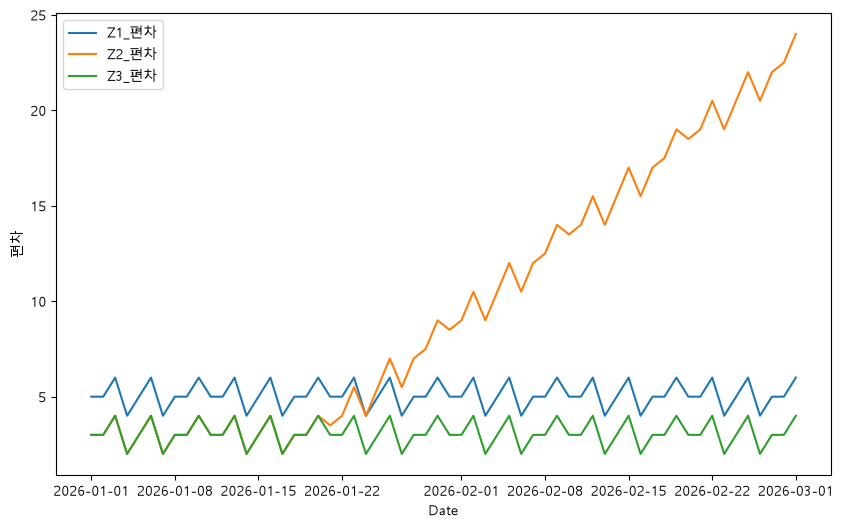

In [186]:
plt.figure(figsize=(10, 6))
plt.plot(furnace["date"], furnace["Z1_편차"], label="Z1_편차")
plt.plot(furnace["date"], furnace["Z2_편차"], label="Z2_편차")
plt.plot(furnace["date"], furnace["Z3_편차"], label="Z3_편차")
plt.xlabel("Date")
plt.ylabel("편차")
plt.legend()
plt.show()

In [ ]:
# TODO 4: Z2 양쪽 온도와 45일 전후 소재 온도·라인 속도를 대조해 해석하세요.


In [195]:
# 45일 전(1~44일)과 후(45~90일)를 행 번호로 나누기 (1일 = 0번 행)
before = furnace.iloc[:44]
after = furnace.iloc[44:]

cols = ["FUR01_Z2_TEMP_L", "FUR01_Z2_TEMP_R", "FUR01_MAT_TEMP", "FUR01_LINE_SPEED"]

# 전/후 평균과 차이
result = pd.DataFrame({
    "45일 전 평균": before[cols].mean(),
    "45일 후 평균": after[cols].mean(),
})
result["차이(후-전)"] = result["45일 후 평균"] - result["45일 전 평균"]
result


,45일 전 평균,45일 후 평균,차이(후-전)
FUR01_Z2_TEMP_L,1221.590909,1208.7500,-12.840909
FUR01_Z2_TEMP_R,1228.090909,1228.1250,0.034091
FUR01_MAT_TEMP,1181.500000,1170.5625,-10.937500
FUR01_LINE_SPEED,12.000000,14.0000,2.000000


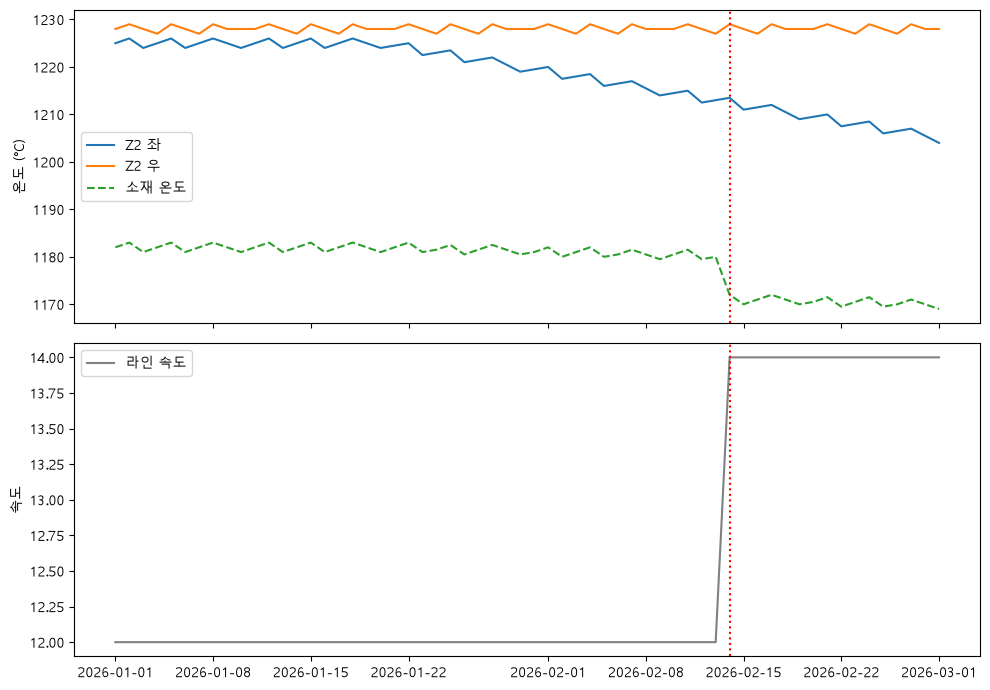

In [199]:

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axes[0].plot(furnace["date"], furnace["FUR01_Z2_TEMP_L"], label="Z2 좌")
axes[0].plot(furnace["date"], furnace["FUR01_Z2_TEMP_R"], label="Z2 우")
axes[0].plot(furnace["date"], furnace["FUR01_MAT_TEMP"], label="소재 온도", linestyle="--")
axes[0].axvline(furnace["date"].iloc[44], color="red", linestyle=":")
axes[0].set_ylabel("온도 (°C)")
axes[0].legend()

axes[1].plot(furnace["date"], furnace["FUR01_LINE_SPEED"], color="gray", label="라인 속도")
axes[1].set_ylabel("속도")
axes[1].axvline(furnace["date"].iloc[44], color="red", linestyle=":")
    
axes[1].legend()

plt.tight_layout()
plt.show()


In [ ]:
실습 2 | 유압·열설비 데이터 해석 (25분)
분석 시작: 03-01_유압_열설비_신호_실습.py
1. 유압 첫 30일과 마지막 10일 평균을 비교한다.
2. 필터 차압(전단-후단)을 계산해 1~30, 31~60, 61~90일의 증가폭을 비교한다.
3. 가열로 각 존의 우측-좌측 편차를 1, 20, 40, 60일에 비교한다.
4. Z2 편차의 위치별 원인 후보와 45일 전후 소재 온도/속도 변화의 관계를 설명한다.

In [ ]:
같은 시점에 라인의 속도 상승과 소재온도의 하락

2존 가열로 좌측 온도센서에서 온도 하락이 관찰됨

현장확인 필요

In [ ]:
좌측 버너 출력과 연료·공기 공급 확인필요
센서 오차

In [203]:
BASE = Path.cwd().parents[1] / "lectures" / "week9" / "3일차실습_20_261109_11"
hyd = pd.read_csv(BASE / "03-01_유압·열설비_신호_유압운전.csv", parse_dates=["date"], encoding="utf-8-sig")
fur = pd.read_csv(BASE / "03-01_유압·열설비_신호_가열로온도.csv", parse_dates=["date"], encoding="utf-8-sig")
tags = pd.read_csv(BASE / "03-01_유압·열설비_신호_계통태그목록.csv", encoding="utf-8-sig")


In [205]:
#[Step 1] 존별 좌우 온도 편차 계산


In [206]:
# 존별 좌우 온도 편차 = 우측 - 좌측 (Z1, Z2, Z3)
for z in ["Z1", "Z2", "Z3"]:
    fur[z + "_편차"] = fur[f"FUR01_{z}_TEMP_R"] - fur[f"FUR01_{z}_TEMP_L"]

# 편차 열만 날짜와 함께 확인
fur[["date", "Z1_편차", "Z2_편차", "Z3_편차"]].head()


,date,Z1_편차,Z2_편차,Z3_편차
0,2026-01-01,5.0,3.0,3.0
1,2026-01-02,5.0,3.0,3.0
2,2026-01-03,6.0,4.0,4.0
3,2026-01-04,4.0,2.0,2.0
4,2026-01-05,5.0,3.0,3.0


In [208]:
fur[["date", "Z1_편차", "Z2_편차", "Z3_편차"]].mean()


date     2026-01-30 12:00:00
Z1_편차                    5.1
Z2_편차               9.933333
Z3_편차                    3.1
dtype: object

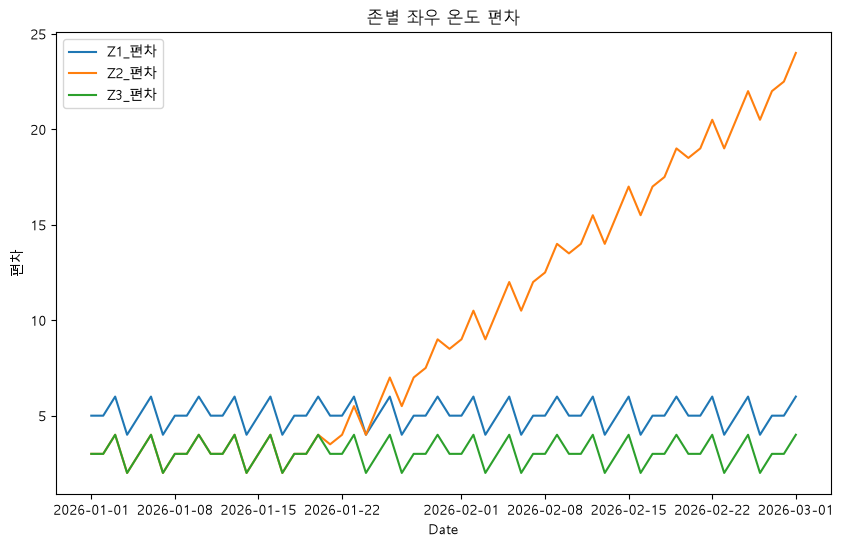

In [209]:
plt.figure(figsize=(10, 6))
plt.plot(fur["date"], fur["Z1_편차"], label="Z1_편차")
plt.plot(fur["date"], fur["Z2_편차"], label="Z2_편차")
plt.plot(fur["date"], fur["Z3_편차"], label="Z3_편차")
plt.title("존별 좌우 온도 편차")
plt.xlabel("Date")
plt.ylabel("편차")
plt.legend()
plt.show()

In [218]:
fur.iloc[0:1][["Z1_편차", "Z2_편차", "Z3_편차"]].mean()


Z1_편차    5.0
Z2_편차    3.0
Z3_편차    3.0
dtype: float64

In [211]:
fur.iloc[:20][["Z1_편차", "Z2_편차", "Z3_편차"]].mean()


Z1_편차    5.1
Z2_편차    3.1
Z3_편차    3.1
dtype: float64

In [ ]:
[Step 2] 시간이 지나며 편차가 어떻게 변하는지 확인
아래 시점의 좌우 온도 편차를 비교하세요.

In [ ]:
fur.iloc[20:40][["Z1_편차", "Z2_편차", "Z3_편차"]].mean()


Z1_편차    5.10
Z2_편차    8.35
Z3_편차    3.10
dtype: float64

In [ ]:
fur.iloc[40:60][["Z1_편차", "Z2_편차", "Z3_편차"]].mean()

Z1_편차     5.10
Z2_편차    18.35
Z3_편차     3.10
dtype: float64

[Step 3] 이상 위치 확인

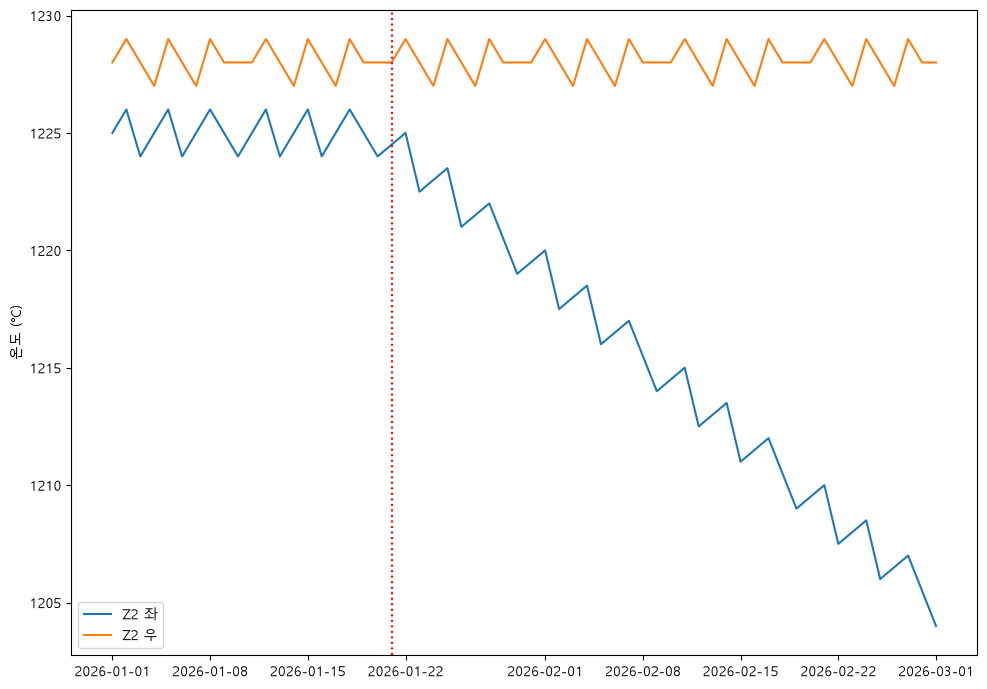

In [ ]:

fig, axes = plt.subplots(1, 1, figsize=(10, 7), sharex=True)

plt.plot(furnace["date"], furnace["FUR01_Z2_TEMP_L"], label="Z2 좌")
plt.plot(furnace["date"], furnace["FUR01_Z2_TEMP_R"], label="Z2 우")

plt.axvline(furnace["date"].iloc[20], color="red", linestyle=":")
plt.ylabel("온도 (°C)")
plt.legend()

plt.tight_layout()
plt.show()


[Step 4] 소재 온도와 라인 속도 비교


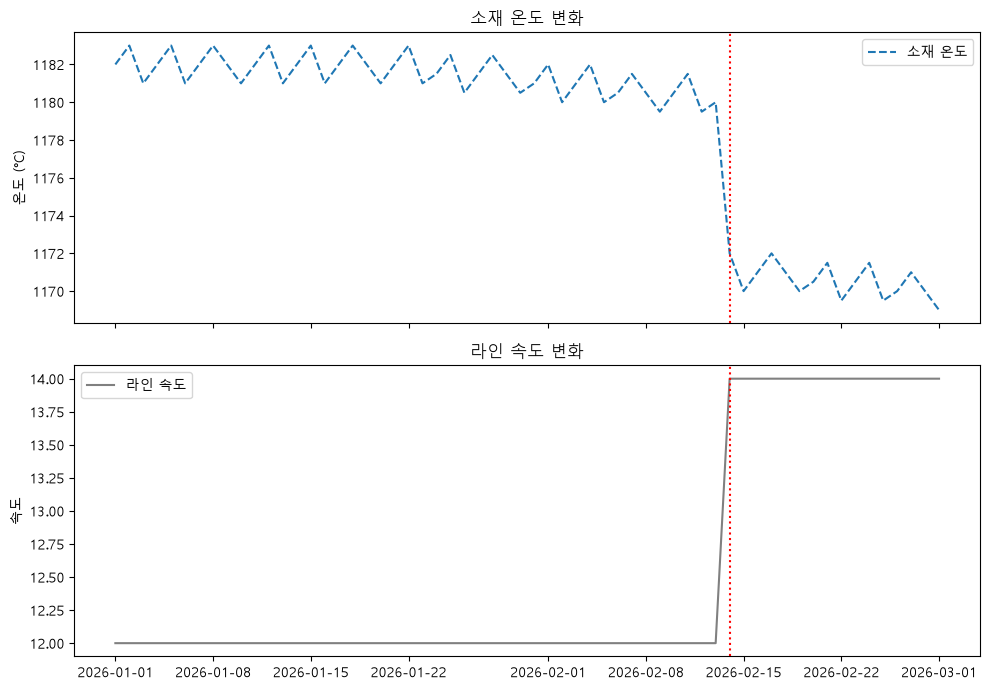

In [235]:

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(furnace["date"], furnace["FUR01_MAT_TEMP"], label="소재 온도", linestyle="--")
axes[0].title.set_text("소재 온도 변화")
axes[0].axvline(furnace["date"].iloc[44], color="red", linestyle=":")
axes[0].set_ylabel("온도 (°C)")
axes[0].legend()

axes[1].title.set_text("라인 속도 변화")
axes[1].plot(furnace["date"], furnace["FUR01_LINE_SPEED"], color="gray", label="라인 속도")
axes[1].set_ylabel("속도")
axes[1].axvline(furnace["date"].iloc[44], color="red", linestyle=":")
    
axes[1].legend()

plt.tight_layout()
plt.show()


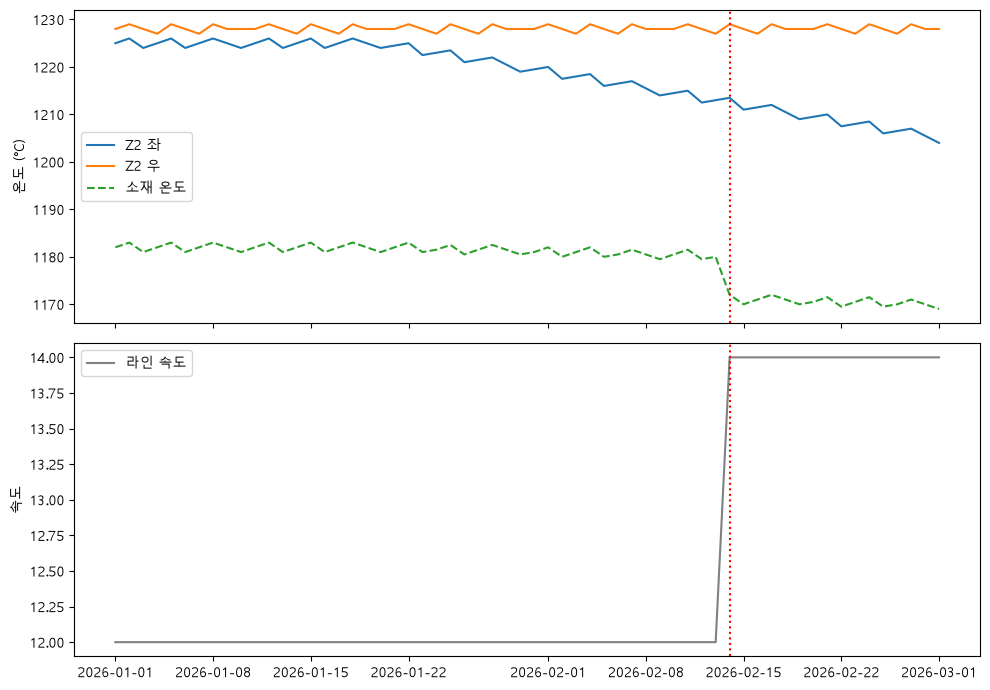

In [238]:

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

axes[0].plot(furnace["date"], furnace["FUR01_Z2_TEMP_L"], label="Z2 좌")
axes[0].plot(furnace["date"], furnace["FUR01_Z2_TEMP_R"], label="Z2 우")
axes[0].plot(furnace["date"], furnace["FUR01_MAT_TEMP"], label="소재 온도", linestyle="--")
axes[0].axvline(furnace["date"].iloc[44], color="red", linestyle=":")
axes[0].set_ylabel("온도 (°C)")
axes[0].legend()

axes[1].plot(furnace["date"], furnace["FUR01_LINE_SPEED"], color="gray", label="라인 속도")
axes[1].set_ylabel("속도")
axes[1].axvline(furnace["date"].iloc[44], color="red", linestyle=":")
    
axes[1].legend()

plt.tight_layout()
plt.show()
